In [1]:
import pandas as pd
import numpy as np


In [2]:
df=pd.read_csv(r"C:\Users\m_hossam\OneDrive\Desktop\insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df["sex"].value_counts()

sex
0    675
1    662
Name: count, dtype: int64

In [24]:
df["age"].value_counts().head(15)

age
18    69
19    67
50    29
51    29
47    29
46    29
45    29
20    29
48    29
52    29
22    28
49    28
54    28
53    28
21    28
Name: count, dtype: int64

In [6]:
df.drop_duplicates(inplace=True)

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['smoker'] = df['smoker'].map({'yes': 1, 'no': 0})

In [9]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,1,southwest,16884.92400
1,18,male,33.770,1,0,southeast,1725.55230
2,28,male,33.000,3,0,southeast,4449.46200
3,33,male,22.705,0,0,northwest,21984.47061
4,32,male,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,0,northwest,10600.54830
1334,18,female,31.920,0,0,northeast,2205.98080
1335,18,female,36.850,0,0,southeast,1629.83350
1336,21,female,25.800,0,0,southwest,2007.94500


In [10]:
df['sex'] = df['sex'].map({'female': 1, 'male': 0})

In [11]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830
1334,18,1,31.920,0,0,northeast,2205.98080
1335,18,1,36.850,0,0,southeast,1629.83350
1336,21,1,25.800,0,0,southwest,2007.94500


In [12]:
df.corr(numeric_only=True)

,age,sex,bmi,children,smoker,charges
age,1.000000,0.019814,0.109344,0.041536,-0.025587,0.298308
sex,0.019814,1.000000,-0.046397,-0.017848,-0.076596,-0.058044
bmi,0.109344,-0.046397,1.000000,0.012755,0.003746,0.198401
children,0.041536,-0.017848,0.012755,1.000000,0.007331,0.067389
smoker,-0.025587,-0.076596,0.003746,0.007331,1.000000,0.787234
charges,0.298308,-0.058044,0.198401,0.067389,0.787234,1.000000


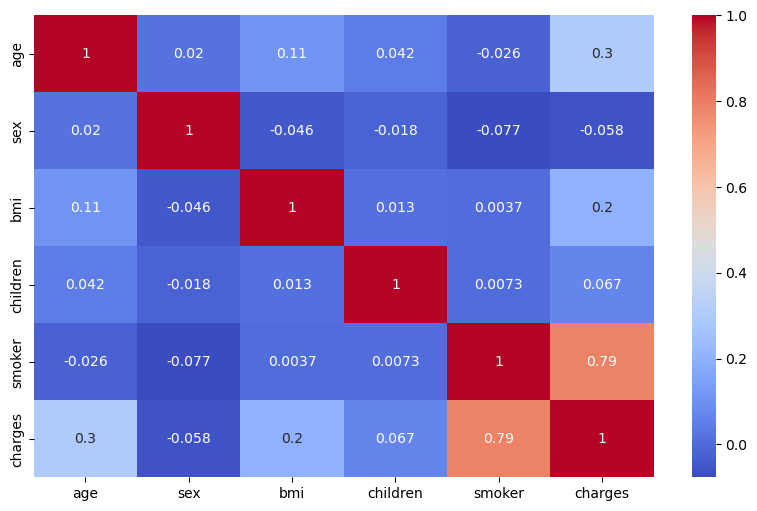

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)
plt.show()


In [14]:
numeric_df = df.select_dtypes(include='number')

In [15]:
correlation = numeric_df.corr()
correlation

,age,sex,bmi,children,smoker,charges
age,1.000000,0.019814,0.109344,0.041536,-0.025587,0.298308
sex,0.019814,1.000000,-0.046397,-0.017848,-0.076596,-0.058044
bmi,0.109344,-0.046397,1.000000,0.012755,0.003746,0.198401
children,0.041536,-0.017848,0.012755,1.000000,0.007331,0.067389
smoker,-0.025587,-0.076596,0.003746,0.007331,1.000000,0.787234
charges,0.298308,-0.058044,0.198401,0.067389,0.787234,1.000000


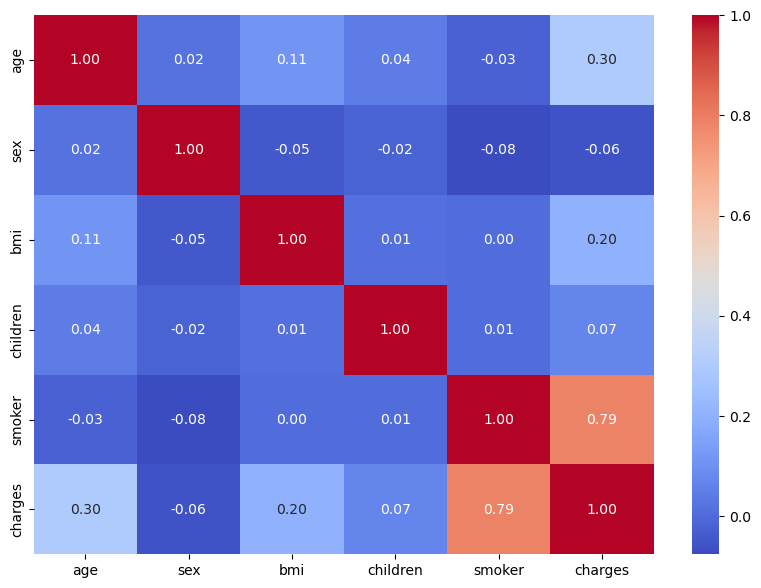

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.show()

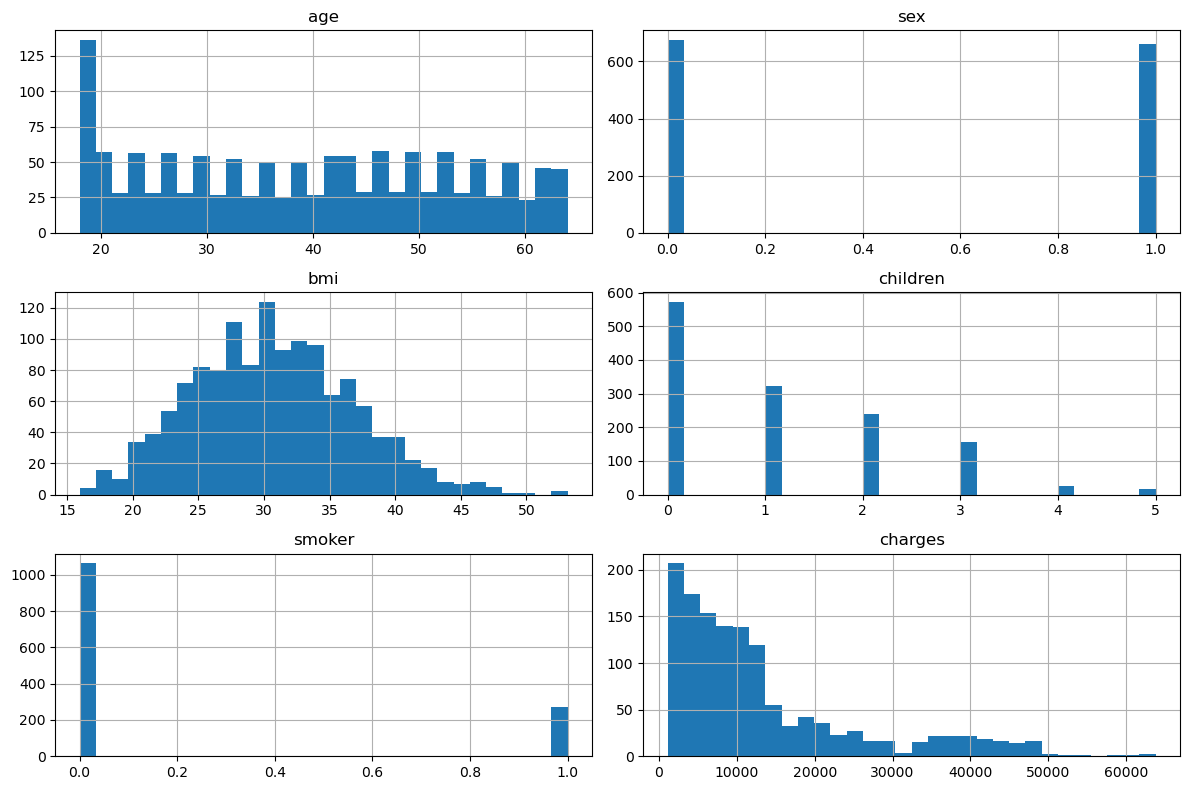

In [17]:
numeric_df.hist(figsize=(12, 8), bins=30)

plt.tight_layout()
plt.show()

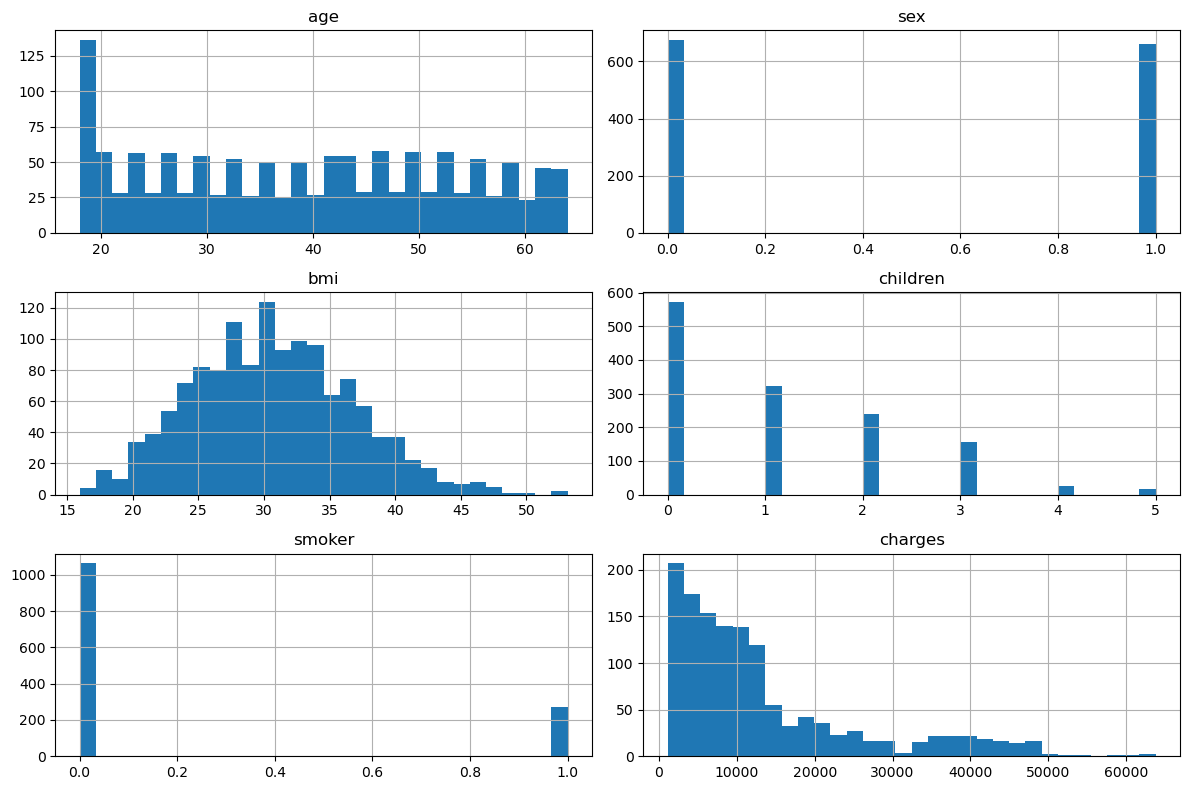

In [18]:
import matplotlib.pyplot as plt

numeric_df.hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

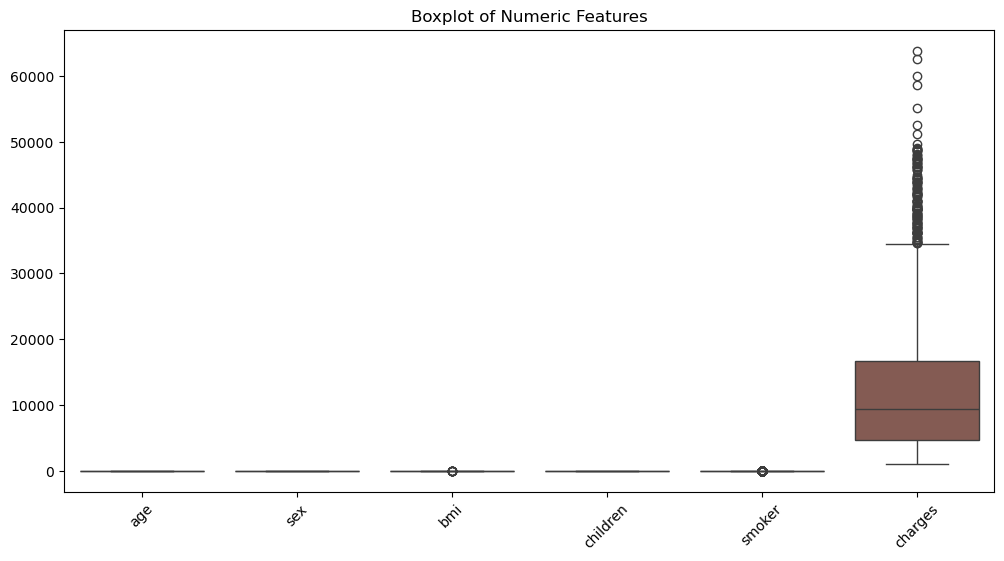

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.boxplot(data=df)

plt.xticks(rotation=45)
plt.title('Boxplot of Numeric Features')
plt.show()

In [25]:
df = pd.get_dummies(df, columns=['region'], drop_first=True)
df

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,True
1,18,0,33.770,1,0,1725.55230,False,True,False
2,28,0,33.000,3,0,4449.46200,False,True,False
3,33,0,22.705,0,0,21984.47061,True,False,False
4,32,0,28.880,0,0,3866.85520,True,False,False
...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,True,False,False
1334,18,1,31.920,0,0,2205.98080,False,False,False
1335,18,1,36.850,0,0,1629.83350,False,True,False
1336,21,1,25.800,0,0,2007.94500,False,False,True


In [20]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830
1334,18,1,31.920,0,0,northeast,2205.98080
1335,18,1,36.850,0,0,southeast,1629.83350
1336,21,1,25.800,0,0,southwest,2007.94500


In [ ]:
X = df.drop('charges', axis=1)
Y = df['charges']

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


In [ ]:
# Split the data into features (X) and target (Y)
X = df.drop('charges', axis=1)
Y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)


In [ ]:
# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)


In [ ]:
# Make predictions
y_pred = model.predict(X_test)

print('First 10 predictions:')
print(y_pred[:10])


In [ ]:
# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE  = {mae:.2f}')
print(f'MSE  = {mse:.2f}')
print(f'RMSE = {rmse:.2f}')
print(f'R2   = {r2:.2f}')


In [ ]:
# Compare actual and predicted charges
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})
results.head(10)
